In [2]:
!pip install seaborn tqdm

import torch
from torch.utils.data import DataLoader, TensorDataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib

from sklearn.model_selection import train_test_split
from sklearn import preprocessing
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    roc_curve, roc_auc_score, precision_recall_curve
)

from tqdm import tqdm

In [3]:
from google.colab import files
files.upload()

Output hidden; open in https://colab.research.google.com to view.

In [4]:
df = pd.read_csv("Train_data.csv")
df.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,class
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal
1,0,udp,other,SF,146,0,0,0,0,0,...,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal
2,0,tcp,private,S0,0,0,0,0,0,0,...,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,anomaly
3,0,tcp,http,SF,232,8153,0,0,0,0,...,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal
4,0,tcp,http,SF,199,420,0,0,0,0,...,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal


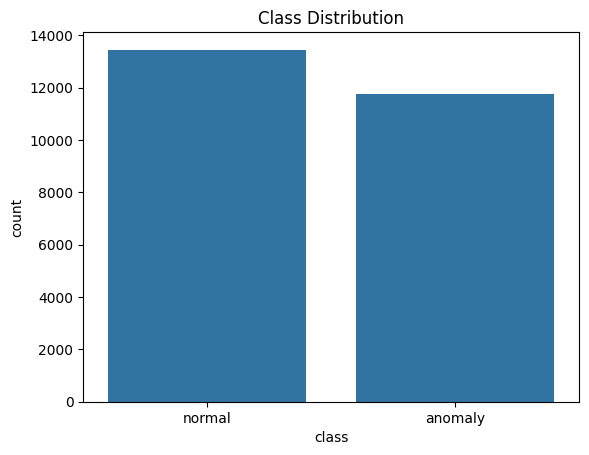

In [5]:
sns.countplot(x=df['class'])
plt.title("Class Distribution")
plt.show()

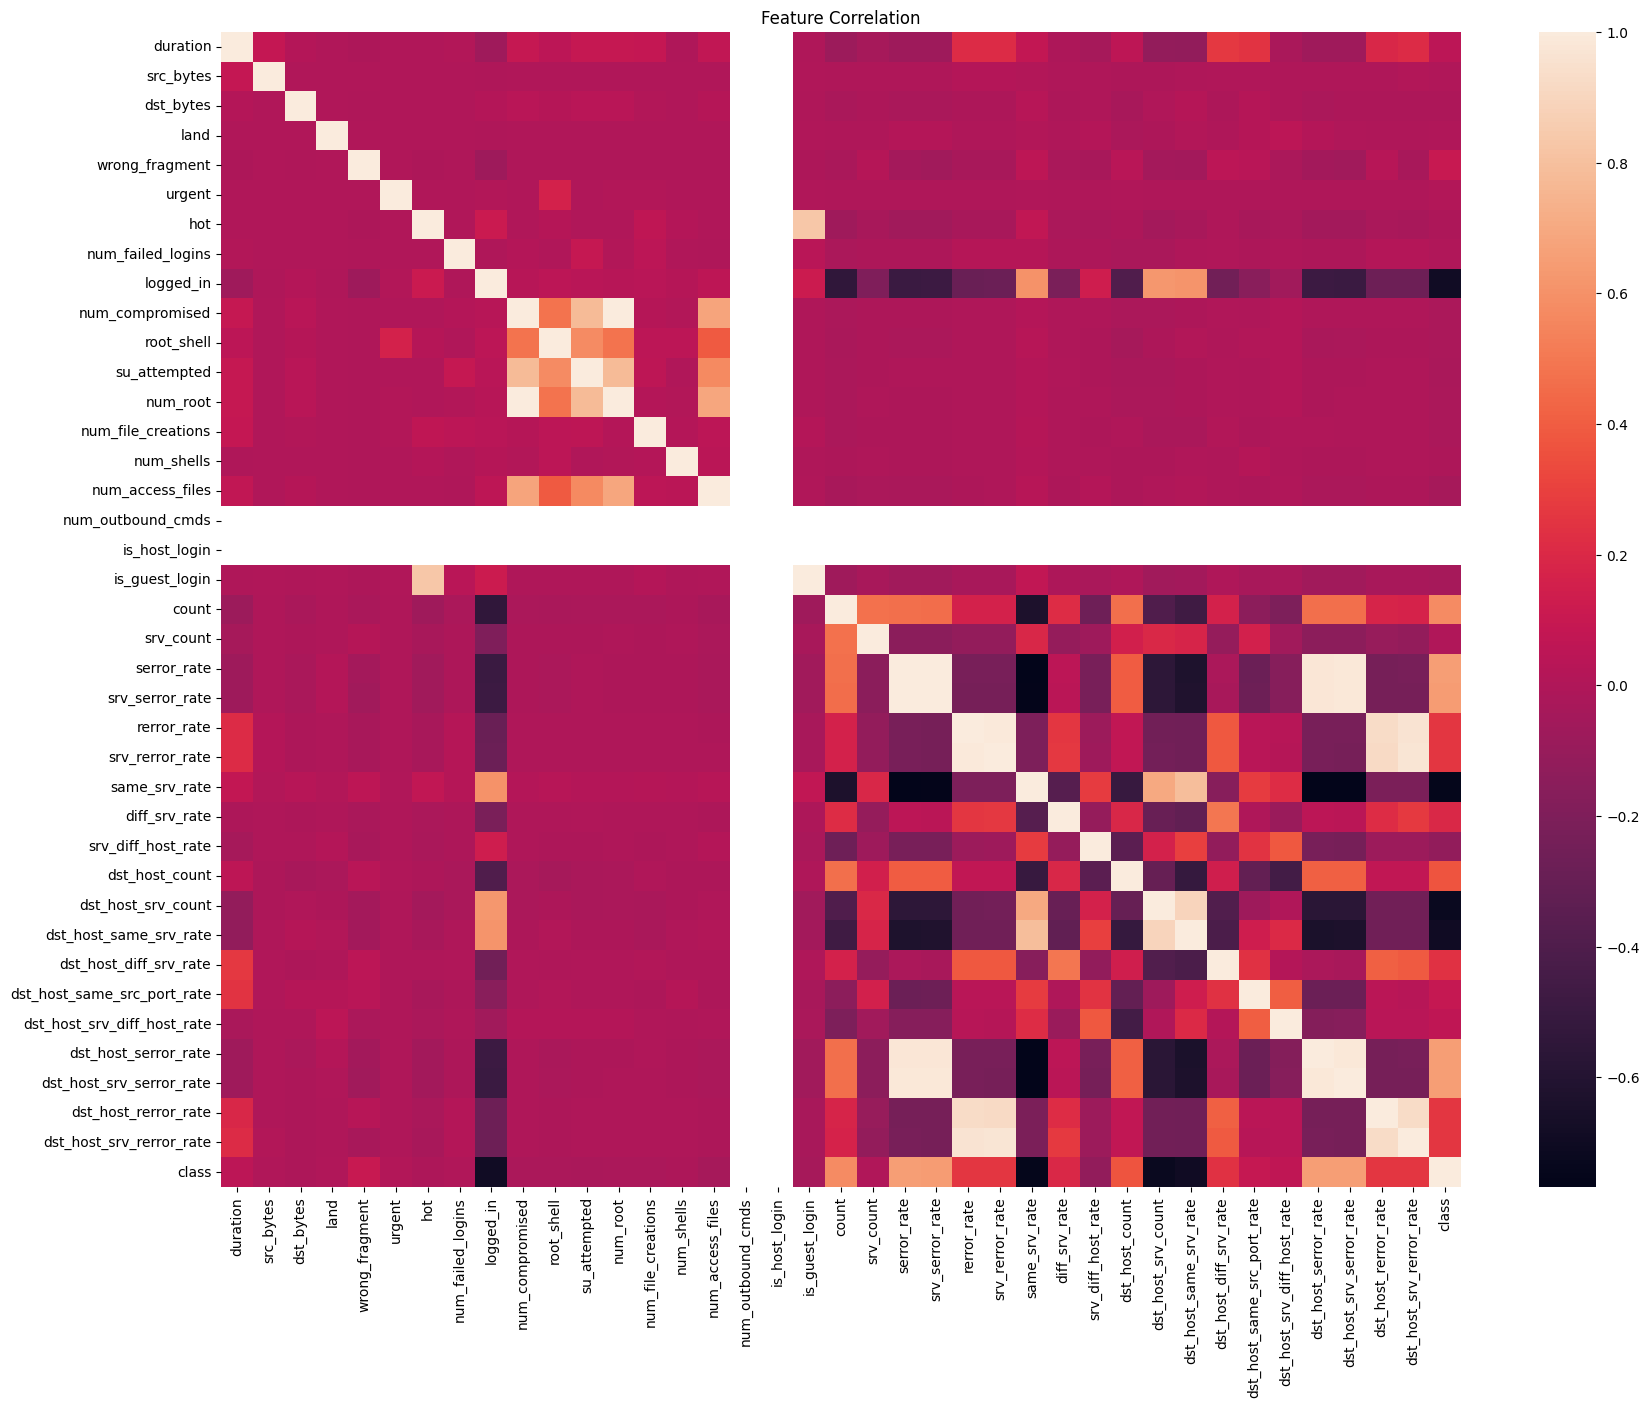

In [6]:
df['class'] = df['class'].apply(lambda x: 0 if x=="normal" else 1)

categorical_columns = ['protocol_type', 'service', 'flag']

plt.figure(figsize=(20,15))
sns.heatmap(df.drop(categorical_columns, axis=1).corr())
plt.title("Feature Correlation")
plt.show()

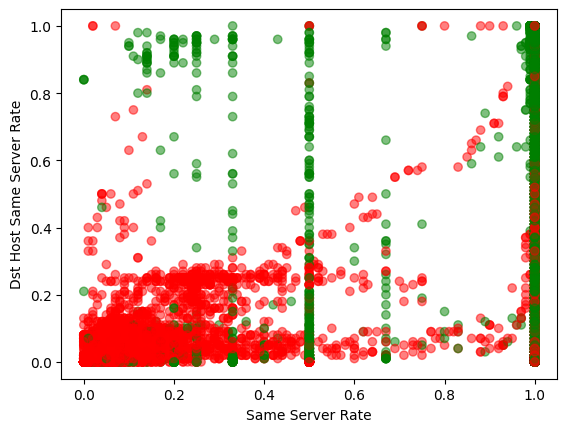

In [7]:
labels = df['class']
colors = ['green','red']

plt.scatter(df['same_srv_rate'], df['dst_host_same_srv_rate'],
            c=labels, cmap=matplotlib.colors.ListedColormap(colors), alpha=0.5)

plt.xlabel("Same Server Rate")
plt.ylabel("Dst Host Same Server Rate")
plt.show()

In [8]:
df = df.join(pd.get_dummies(df[categorical_columns]))
df.drop(categorical_columns, axis=1, inplace=True)

In [9]:
X = df.drop('class', axis=1)
y = df['class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=12
)

In [10]:
scaler = preprocessing.StandardScaler()
X_train_norm = scaler.fit_transform(X_train)
X_test_norm = scaler.transform(X_test)

In [11]:
pca = PCA(n_components=10)

X_train_PCA = pca.fit_transform(X_train_norm)
X_test_PCA = pca.transform(X_test_norm)

print("Explained Variance:", pca.explained_variance_ratio_)

Explained Variance: [0.0834838  0.05251576 0.03534561 0.03201952 0.02585132 0.02270669
 0.0190815  0.01514541 0.01369868 0.01253217]


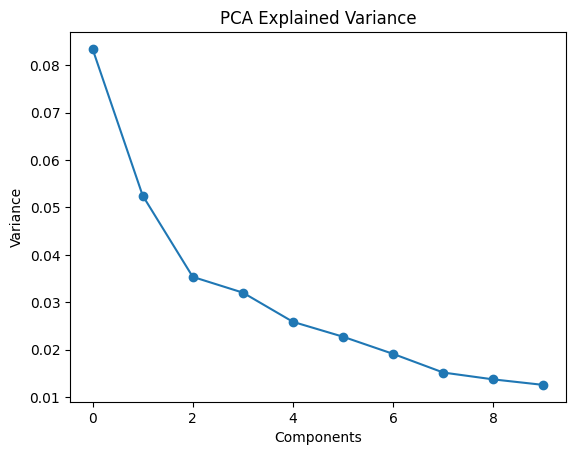

In [12]:
plt.plot(pca.explained_variance_ratio_, marker='o')
plt.title("PCA Explained Variance")
plt.xlabel("Components")
plt.ylabel("Variance")
plt.show()

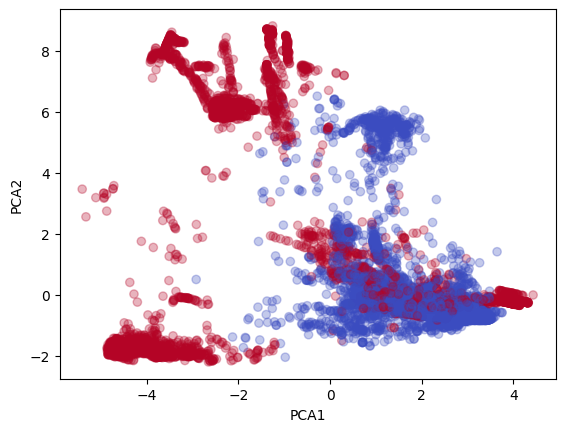

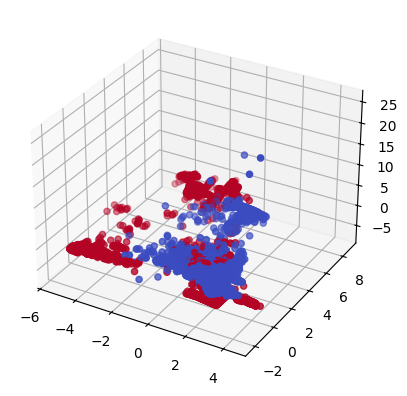

In [13]:
x = X_train_PCA[:,0]
y_ = X_train_PCA[:,1]
z = X_train_PCA[:,2]

labels = y_train

plt.scatter(x, y_, c=labels, cmap='coolwarm', alpha=0.3)
plt.xlabel("PCA1")
plt.ylabel("PCA2")
plt.show()

fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.scatter(x, y_, z, c=labels, cmap='coolwarm')
plt.show()

In [14]:
def full_evaluation(y_true, y_pred, y_prob, model_name):

    print(f"\n===== {model_name} =====")

    print("Accuracy :", accuracy_score(y_true, y_pred))
    print("Precision:", precision_score(y_true, y_pred))
    print("Recall   :", recall_score(y_true, y_pred))
    print("F1 Score :", f1_score(y_true, y_pred))

    print("\nClassification Report:\n")
    print(classification_report(y_true, y_pred))

    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt="d")
    plt.title(f"{model_name} Confusion Matrix")
    plt.show()

    # ROC Curve
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    auc = roc_auc_score(y_true, y_prob)

    plt.plot(fpr, tpr, label=f"AUC={auc:.4f}")
    plt.plot([0,1],[0,1])
    plt.legend()
    plt.title(f"{model_name} ROC Curve")
    plt.show()

    # Precision Recall Curve
    precision, recall, _ = precision_recall_curve(y_true, y_prob)
    plt.plot(recall, precision)
    plt.title(f"{model_name} PR Curve")
    plt.show()

    print("AUC Score:", auc)


===== Logistic Regression =====
Accuracy : 0.9565389958325065
Precision: 0.9656538969616909
Recall   : 0.9395886889460154
F1 Score : 0.952442996742671

Classification Report:

              precision    recall  f1-score   support

           0       0.95      0.97      0.96      2705
           1       0.97      0.94      0.95      2334

    accuracy                           0.96      5039
   macro avg       0.96      0.96      0.96      5039
weighted avg       0.96      0.96      0.96      5039



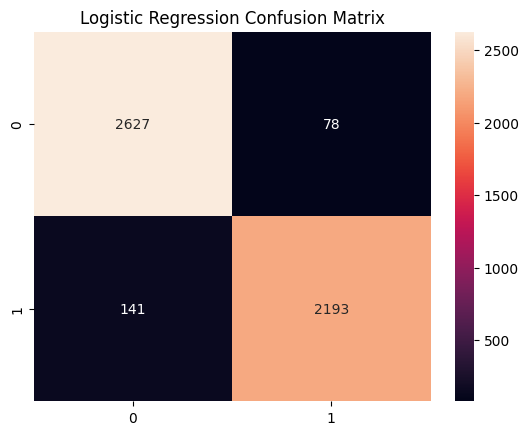

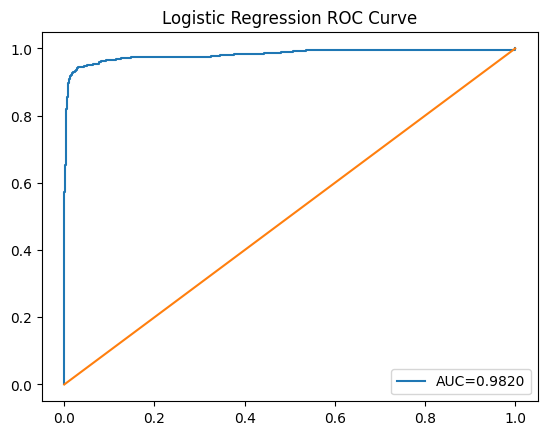

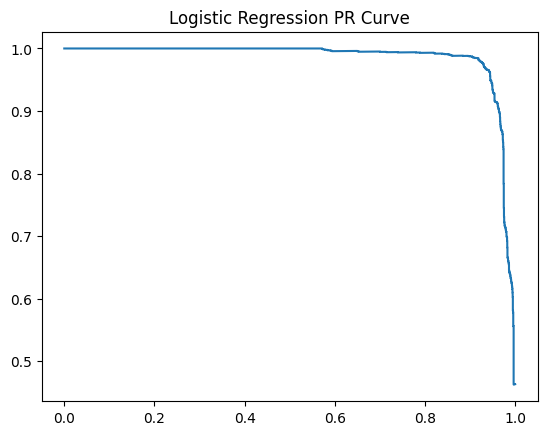

AUC Score: 0.9819599998099301


In [15]:
lr = LogisticRegression(max_iter=200)
lr.fit(X_train_PCA, y_train)

y_pred_lr = lr.predict(X_test_PCA)
y_prob_lr = lr.predict_proba(X_test_PCA)[:,1]

full_evaluation(y_test, y_pred_lr, y_prob_lr, "Logistic Regression")

In [16]:
class SimpleNN(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = torch.nn.Linear(X_train_norm.shape[1], 20)
        self.fc2 = torch.nn.Linear(20, 10)
        self.fc3 = torch.nn.Linear(10, 1)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = torch.sigmoid(self.fc3(x))
        return x

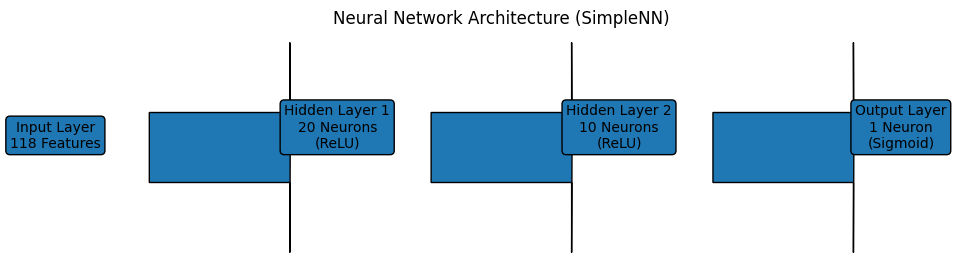

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,3))

# Layer boxes
plt.text(0, 0, "Input Layer\n118 Features", ha='center', bbox=dict(boxstyle="round"))
plt.text(3, 0, "Hidden Layer 1\n20 Neurons\n(ReLU)", ha='center', bbox=dict(boxstyle="round"))
plt.text(6, 0, "Hidden Layer 2\n10 Neurons\n(ReLU)", ha='center', bbox=dict(boxstyle="round"))
plt.text(9, 0, "Output Layer\n1 Neuron\n(Sigmoid)", ha='center', bbox=dict(boxstyle="round"))

# Arrows
plt.arrow(1, 0, 1.5, 0, length_includes_head=True)
plt.arrow(4, 0, 1.5, 0, length_includes_head=True)
plt.arrow(7, 0, 1.5, 0, length_includes_head=True)

plt.title("Neural Network Architecture (SimpleNN)")
plt.axis('off')
plt.show()

In [18]:
model = SimpleNN()
criterion = torch.nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

X_train_t = torch.tensor(X_train_norm, dtype=torch.float32)
y_train_t = torch.tensor(y_train.values, dtype=torch.float32)

dataset = TensorDataset(X_train_t, y_train_t)
loader = DataLoader(dataset, batch_size=64, shuffle=True)

train_loss = []
test_loss = []

X_test_t = torch.tensor(X_test_norm, dtype=torch.float32)
y_test_t = torch.tensor(y_test.values, dtype=torch.float32)

for epoch in range(5):
    model.train()
    loss_epoch = 0

    for x_batch, y_batch in loader:
        optimizer.zero_grad()
        pred = model(x_batch).squeeze()
        loss = criterion(pred, y_batch)
        loss.backward()
        optimizer.step()
        loss_epoch += loss.item()

    train_loss.append(loss_epoch/len(loader))

    model.eval()
    with torch.no_grad():
        test_pred = model(X_test_t).squeeze()
        loss_test = criterion(test_pred, y_test_t)
        test_loss.append(loss_test.item())

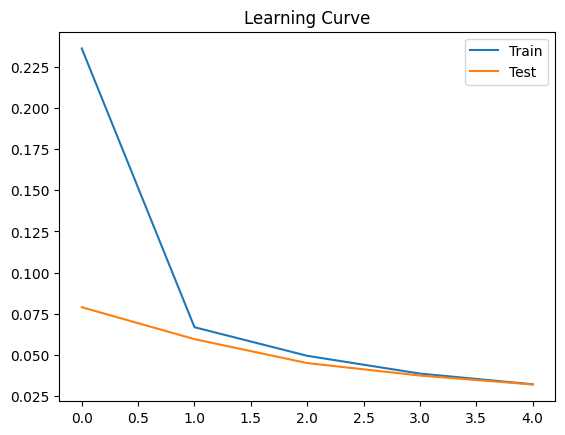

In [19]:
plt.plot(train_loss, label="Train")
plt.plot(test_loss, label="Test")
plt.legend()
plt.title("Learning Curve")
plt.show()


===== Neural Network =====
Accuracy : 0.9884897797181981
Precision: 0.983843537414966
Recall   : 0.9914310197086547
F1 Score : 0.9876227059325651

Classification Report:

              precision    recall  f1-score   support

           0       0.99      0.99      0.99      2705
           1       0.98      0.99      0.99      2334

    accuracy                           0.99      5039
   macro avg       0.99      0.99      0.99      5039
weighted avg       0.99      0.99      0.99      5039



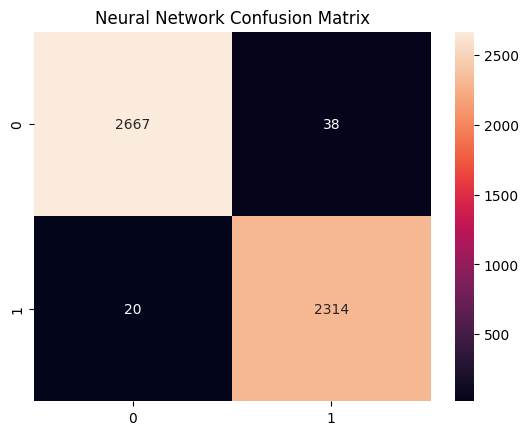

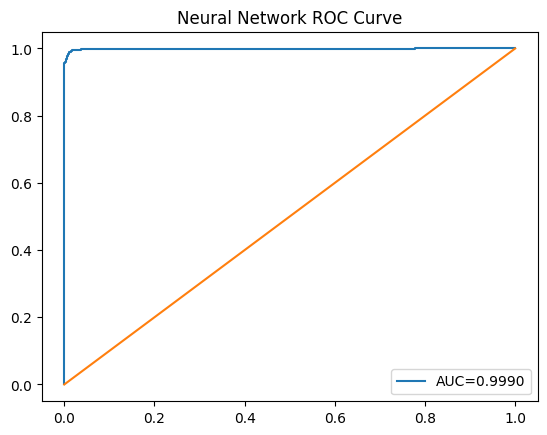

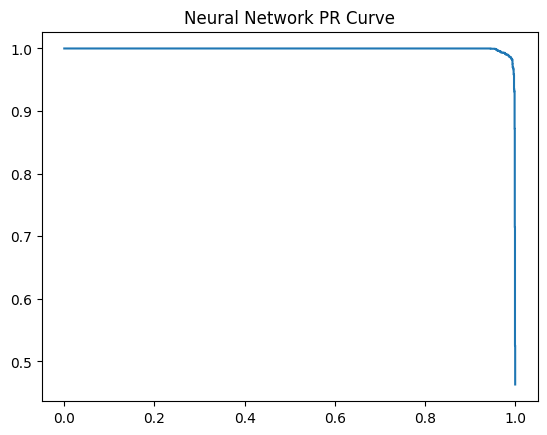

AUC Score: 0.9990195565988275


In [20]:
model.eval()
with torch.no_grad():
    preds = model(X_test_t).squeeze()

    y_prob_nn = preds.numpy()
    y_pred_nn = (preds > 0.5).int().numpy()

full_evaluation(y_test, y_pred_nn, y_prob_nn, "Neural Network")

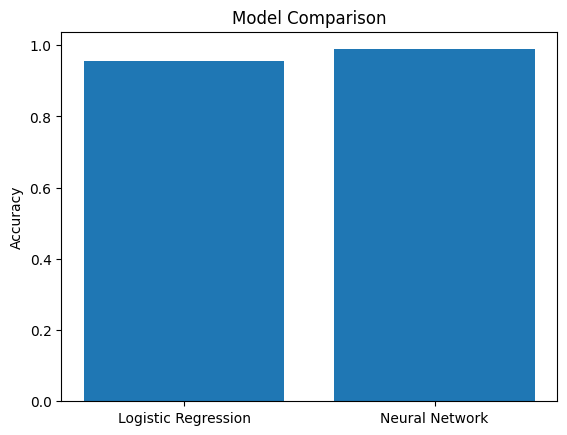

In [21]:
models = ["Logistic Regression", "Neural Network"]

accuracy_scores = [
    accuracy_score(y_test, y_pred_lr),
    accuracy_score(y_test, y_pred_nn)
]

plt.bar(models, accuracy_scores)
plt.title("Model Comparison")
plt.ylabel("Accuracy")
plt.show()

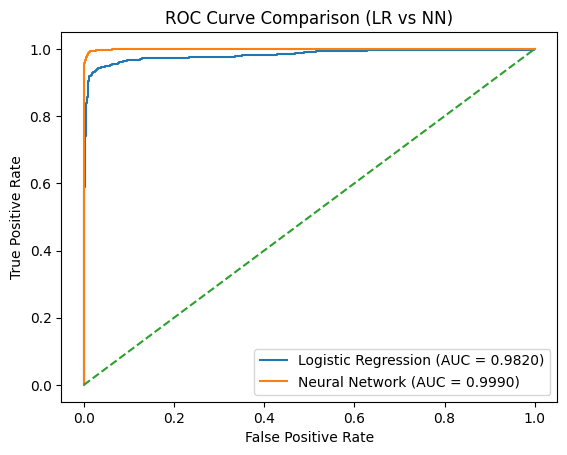

In [22]:
# Compute ROC for Logistic Regression
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
auc_lr = roc_auc_score(y_test, y_prob_lr)

# Compute ROC for Neural Network
fpr_nn, tpr_nn, _ = roc_curve(y_test, y_prob_nn)
auc_nn = roc_auc_score(y_test, y_prob_nn)

# Plot both together
plt.figure()

plt.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC = {auc_lr:.4f})")
plt.plot(fpr_nn, tpr_nn, label=f"Neural Network (AUC = {auc_nn:.4f})")

# Random baseline
plt.plot([0,1], [0,1], linestyle='--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison (LR vs NN)")
plt.legend()
plt.show()

In [23]:
from sklearn.metrics import roc_curve

# For Neural Network (you can do same for LR)
fpr, tpr, thresholds = roc_curve(y_test, y_prob_nn)

# Compute J statistic
J = tpr - fpr

# Best threshold
ix = np.argmax(J)
best_threshold = thresholds[ix]

print("Best Threshold:", best_threshold)
print("TPR (Recall):", tpr[ix])
print("FPR:", fpr[ix])

Best Threshold: 0.5134094
TPR (Recall): 0.9910025706940874
FPR: 0.012569316081330868


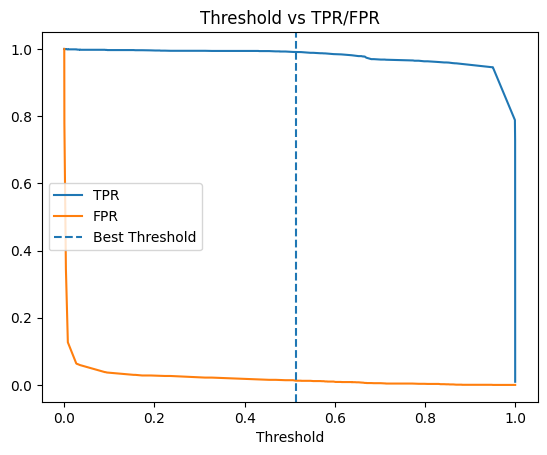

In [24]:
plt.plot(thresholds, tpr, label="TPR")
plt.plot(thresholds, fpr, label="FPR")
plt.axvline(best_threshold, linestyle='--', label="Best Threshold")

plt.xlabel("Threshold")
plt.title("Threshold vs TPR/FPR")
plt.legend()
plt.show()


===== NN (Tuned Threshold) =====
Accuracy : 0.9890851359396706
Precision: 0.9855134213890072
Recall   : 0.9910025706940874
F1 Score : 0.9882503738517411

Classification Report:

              precision    recall  f1-score   support

           0       0.99      0.99      0.99      2705
           1       0.99      0.99      0.99      2334

    accuracy                           0.99      5039
   macro avg       0.99      0.99      0.99      5039
weighted avg       0.99      0.99      0.99      5039



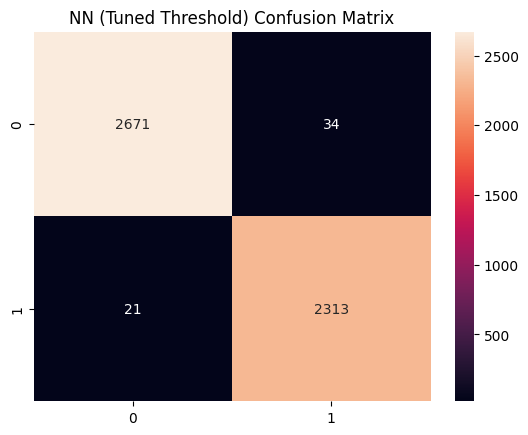

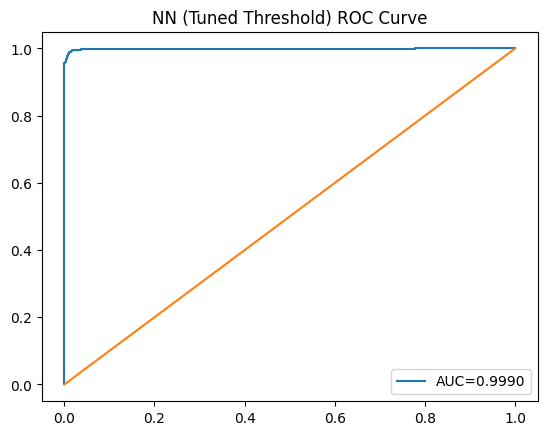

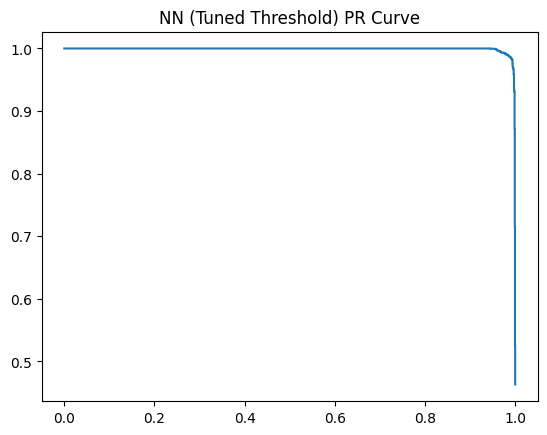

AUC Score: 0.9990195565988275


In [25]:
y_pred_new = (y_prob_nn >= best_threshold).astype(int)

full_evaluation(y_test, y_pred_new, y_prob_nn, "NN (Tuned Threshold)")

In [26]:
class TunableNN(torch.nn.Module):
    def __init__(self, input_size, hidden1, hidden2):
        super().__init__()
        self.fc1 = torch.nn.Linear(input_size, hidden1)
        self.fc2 = torch.nn.Linear(hidden1, hidden2)
        self.fc3 = torch.nn.Linear(hidden2, 1)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = torch.sigmoid(self.fc3(x))
        return x

In [27]:
def train_model(lr, hidden1, hidden2, batch_size):

    model = TunableNN(X_train_norm.shape[1], hidden1, hidden2)

    criterion = torch.nn.BCELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    dataset = TensorDataset(
        torch.tensor(X_train_norm, dtype=torch.float32),
        torch.tensor(y_train.values, dtype=torch.float32)
    )

    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

    # Train (short training for tuning)
    for epoch in range(3):
        for x_batch, y_batch in loader:
            optimizer.zero_grad()
            pred = model(x_batch).squeeze()
            loss = criterion(pred, y_batch)
            loss.backward()
            optimizer.step()

    # Evaluate
    model.eval()
    with torch.no_grad():
        preds = model(torch.tensor(X_test_norm, dtype=torch.float32)).squeeze()
        y_pred = (preds > 0.5).int().numpy()
        acc = accuracy_score(y_test, y_pred)

    return acc

In [28]:
learning_rates = [0.01, 0.001]
hidden1_list = [20, 50]
hidden2_list = [10, 25]
batch_sizes = [32, 64]

best_acc = 0
best_params = None

for lr in learning_rates:
    for h1 in hidden1_list:
        for h2 in hidden2_list:
            for bs in batch_sizes:

                acc = train_model(lr, h1, h2, bs)

                print(f"lr={lr}, h1={h1}, h2={h2}, bs={bs} → acc={acc:.4f}")

                if acc > best_acc:
                    best_acc = acc
                    best_params = (lr, h1, h2, bs)

print("\nBest Parameters:", best_params)
print("Best Accuracy:", best_acc)

lr=0.01, h1=20, h2=10, bs=32 → acc=0.9879
lr=0.01, h1=20, h2=10, bs=64 → acc=0.9907
lr=0.01, h1=20, h2=25, bs=32 → acc=0.9893
lr=0.01, h1=20, h2=25, bs=64 → acc=0.9903
lr=0.01, h1=50, h2=10, bs=32 → acc=0.9847
lr=0.01, h1=50, h2=10, bs=64 → acc=0.9881
lr=0.01, h1=50, h2=25, bs=32 → acc=0.9901
lr=0.01, h1=50, h2=25, bs=64 → acc=0.9895
lr=0.001, h1=20, h2=10, bs=32 → acc=0.9837
lr=0.001, h1=20, h2=10, bs=64 → acc=0.9825
lr=0.001, h1=20, h2=25, bs=32 → acc=0.9905
lr=0.001, h1=20, h2=25, bs=64 → acc=0.9819
lr=0.001, h1=50, h2=10, bs=32 → acc=0.9841
lr=0.001, h1=50, h2=10, bs=64 → acc=0.9865
lr=0.001, h1=50, h2=25, bs=32 → acc=0.9891
lr=0.001, h1=50, h2=25, bs=64 → acc=0.9909

Best Parameters: (0.001, 50, 25, 64)
Best Accuracy: 0.9908712046040881



===== Tuned Neural Network =====
Accuracy : 0.9884897797181981
Precision: 0.983843537414966
Recall   : 0.9914310197086547
F1 Score : 0.9876227059325651

Classification Report:

              precision    recall  f1-score   support

           0       0.99      0.99      0.99      2705
           1       0.98      0.99      0.99      2334

    accuracy                           0.99      5039
   macro avg       0.99      0.99      0.99      5039
weighted avg       0.99      0.99      0.99      5039



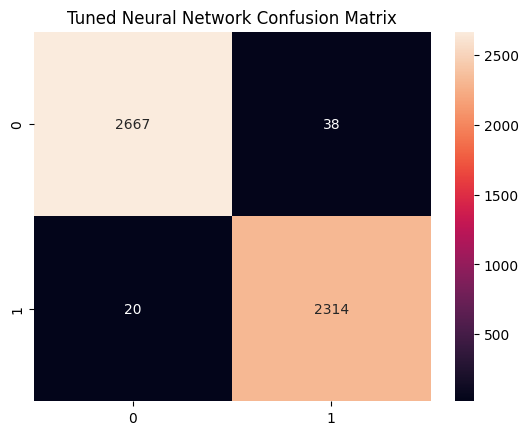

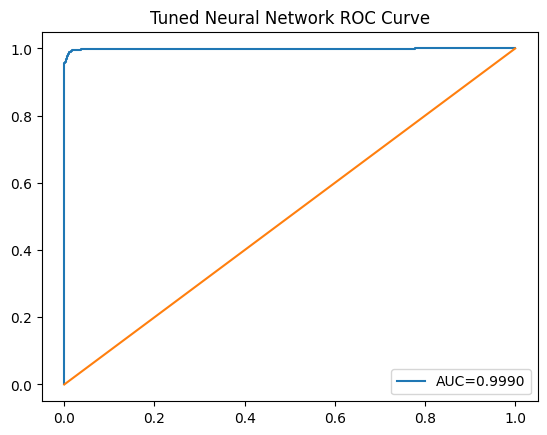

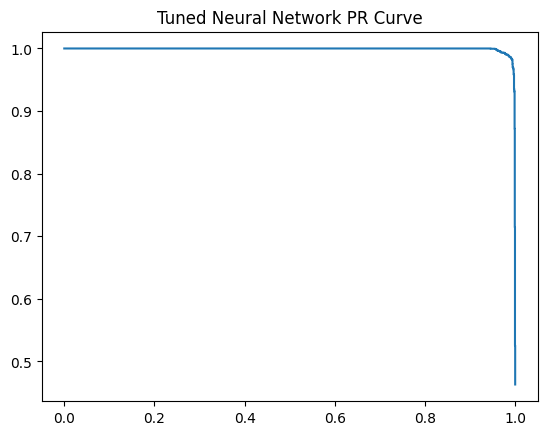

AUC Score: 0.9990195565988275


In [29]:
model.eval()
with torch.no_grad():
    preds = model(torch.tensor(X_test_norm, dtype=torch.float32)).squeeze()

    y_prob = preds.numpy()
    y_pred = (preds > 0.5).int().numpy()

full_evaluation(y_test, y_pred, y_prob, "Tuned Neural Network")


===== FINAL TUNED MODEL (NN + Threshold) =====
Accuracy : 0.9912681087517364
Precision: 0.9931093884582257
Recall   : 0.9880034275921166
F1 Score : 0.9905498281786942

Classification Report:

              precision    recall  f1-score   support

           0       0.99      0.99      0.99      2705
           1       0.99      0.99      0.99      2334

    accuracy                           0.99      5039
   macro avg       0.99      0.99      0.99      5039
weighted avg       0.99      0.99      0.99      5039



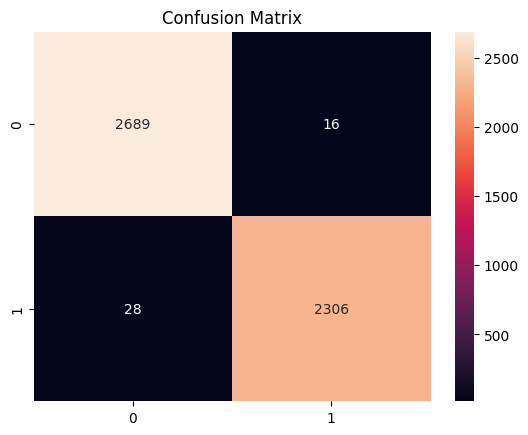

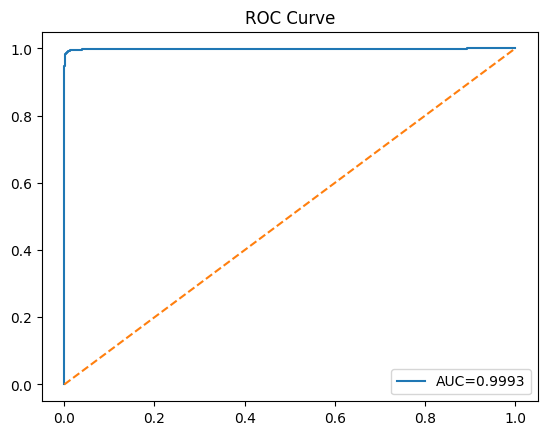

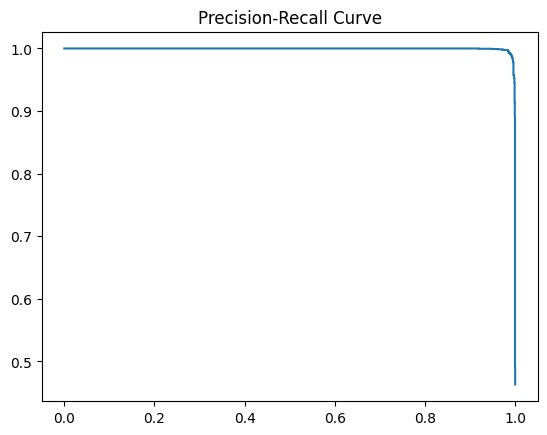

AUC Score: 0.9992636379043538


In [30]:
# ===== FINAL TUNED MODEL (NN + THRESHOLD) =====

# Best hyperparameters
lr, h1, h2, bs = 0.001, 50, 25, 64
best_threshold = 0.5134094

# Model definition
class TunableNN(torch.nn.Module):
    def __init__(self, input_size, hidden1, hidden2):
        super().__init__()
        self.fc1 = torch.nn.Linear(input_size, hidden1)
        self.fc2 = torch.nn.Linear(hidden1, hidden2)
        self.fc3 = torch.nn.Linear(hidden2, 1)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = torch.sigmoid(self.fc3(x))
        return x

# Initialize model
model = TunableNN(X_train_norm.shape[1], h1, h2)

# Setup training
optimizer = torch.optim.Adam(model.parameters(), lr=lr)
criterion = torch.nn.BCELoss()

dataset = TensorDataset(
    torch.tensor(X_train_norm, dtype=torch.float32),
    torch.tensor(y_train.values, dtype=torch.float32)
)

loader = DataLoader(dataset, batch_size=bs, shuffle=True)

# Train
for epoch in range(5):
    for x_batch, y_batch in loader:
        optimizer.zero_grad()
        pred = model(x_batch).squeeze()
        loss = criterion(pred, y_batch)
        loss.backward()
        optimizer.step()

# Predict
model.eval()
with torch.no_grad():
    preds = model(torch.tensor(X_test_norm, dtype=torch.float32)).squeeze()

    y_prob = preds.numpy()
    y_pred = (y_prob >= best_threshold).astype(int)

# ===== FULL EVALUATION =====
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, roc_curve, roc_auc_score, precision_recall_curve
import seaborn as sns
import matplotlib.pyplot as plt

print("\n===== FINAL TUNED MODEL (NN + Threshold) =====")

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d")
plt.title("Confusion Matrix")
plt.show()

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.plot(fpr, tpr, label=f"AUC={auc:.4f}")
plt.plot([0,1],[0,1],'--')
plt.legend()
plt.title("ROC Curve")
plt.show()

# PR Curve
precision, recall, _ = precision_recall_curve(y_test, y_prob)
plt.plot(recall, precision)
plt.title("Precision-Recall Curve")
plt.show()

print("AUC Score:", auc)